# Modelo final

**Objetivo.** Entrenar, justificar y evaluar el **modelo final** del proyecto incorporando lo que aprendimos en los cuadernos `03_preprocesamiento`, `05_hiperparametros` y `07_evaluacion`:

- quitar `MKT_margin` (variable que cambia con el año, PSI 0.6–1.5);
- probar **Pinnacle** (la casa de menor margen) como precio de referencia, con el consenso de las demás casas como respaldo cuando Pinnacle no publica;
- elegir el hiperparámetro de regularización con **validación temporal anidada**;
- evaluar con **todas** las métricas: log loss, RPS, Brier, AUC, ECE, pendiente de calibración, por temporada y por liga, con intervalos por bloques y corrección de Benjamini–Hochberg;
- entrenar con todos los datos, **guardar** el modelo y mostrar cómo usarlo con cuotas nuevas.

**Cómo leer este cuaderno.** Cada celda de código va precedida por una celda de texto (qué vamos a hacer y por qué) y seguida por otra (qué encontramos y qué puede significar para nuestro caso).

| Paso | Qué hace |
|---|---|
| 0 | Carga y utilidades |
| 1 | Construcción del precio de referencia (Pinnacle con respaldo de consenso) |
| 2 | Candidatos y regla de elección del modelo final |
| 3 | Elección de la regularización con validación anidada |
| 4 | Evaluación completa fuera de muestra (8 temporadas) |
| 5 | Diagnóstico: curvas ROC, calibración, estabilidad y desempeño por liga |
| 6 | Backtest de apuestas |
| 7 | Entrenamiento final, guardado y uso con cuotas nuevas |

**Entrada.** `dataset_final.csv`, `matches_sq.csv`, `backtest_odds.csv`, `feature_sets.json`, `modelos_oof.csv`. **Salida.** `modelo_final.json` (coeficientes y escalado), `modelo_final.joblib`, `modelo_final_oof.csv` (predicciones fuera de muestra).

## Paso 0 — Carga y utilidades

**Qué vamos a hacer.** Cargar los datos y definir las utilidades que se reutilizan: validación temporal expansiva (8 folds, 2018/19–2025/26), métricas (log loss, RPS, Brier, AUC, ECE) y comparación pareada con intervalo por **bootstrap de bloques** (temporada–semana) con corrección de Benjamini–Hochberg.

**Por qué.** Para que el modelo final se mida con exactamente la misma vara que todo lo anterior y los números sean comparables con `04_modelo` y `07_evaluacion`.

In [1]:
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import log_loss, roc_auc_score, roc_curve, accuracy_score, balanced_accuracy_score

warnings.filterwarnings('ignore')
DATA = '../data/'
df = pd.read_csv(DATA + 'dataset_final.csv'); odds = pd.read_csv(DATA + 'backtest_odds.csv')
fs = json.load(open(DATA + 'feature_sets.json')); HP = json.load(open(DATA + 'hiperparametros.json'))
y = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy(); seas = df['Season'].to_numpy(); liga = df['Div'].to_numpy()
TEMP = sorted(np.unique(seas)); FOLDS = [s for s in TEMP if s >= 1819]; EV = seas >= 1819
fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
bloque = pd.factorize(df['Season'].astype(str) + '-' + fechas.dt.isocalendar().week.astype(str).to_numpy())[0]
rng = np.random.default_rng(88)

def cv_proba(fab, X, folds=FOLDS):
    Pm = np.full((len(y), 3), np.nan)
    for s in folds:
        tr, va = seas < s, seas == s
        Pm[va] = fab().fit(X[tr], y[tr]).predict_proba(X[va])
    return Pm
def loss_vec(Pm):
    o = np.full(len(y), np.nan); ok = ~np.isnan(Pm[:, 0]); o[ok] = -np.log(np.clip(Pm[ok, y[ok]], 1e-9, 1)); return o
def rps(Pm, yv):
    O = np.eye(3)[yv]; return float(np.mean(0.5 * (((np.cumsum(Pm, 1) - np.cumsum(O, 1))[:, :2]) ** 2).sum(1)))
def brier(Pm, yv): return float(np.mean(np.sum((Pm - np.eye(3)[yv]) ** 2, axis=1)))
def aucs(Pm, yv): return [roc_auc_score(yv == j, Pm[:, j]) for j in range(3)]
def ece_w(p, o, nb=10):
    b = np.minimum((p * nb).astype(int), nb - 1); return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def ece_q(p, o, nb=10):
    b = pd.qcut(p, nb, labels=False, duplicates='drop'); return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def pend(p, o):
    pc = np.clip(p, 1e-6, 1 - 1e-6); m = LogisticRegression(C=1e6, max_iter=1000).fit(np.log(pc / (1 - pc)).reshape(-1, 1), o); return float(m.coef_[0, 0])
def comparar(la, lb, B=2000, mask=None):
    ok = ~np.isnan(la) & ~np.isnan(lb)
    if mask is not None: ok &= mask
    d = (la - lb)[ok]; b = bloque[ok]; cod, K = pd.factorize(b)[0], len(np.unique(b))
    sm = np.bincount(cod, weights=d, minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    ix = rng.integers(0, K, (B, K)); bs = sm[ix].sum(1) / cn[ix].sum(1); fo = pd.Series(d).groupby(seas[ok]).mean()
    p = float(max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1 / B))
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), folds=f'{int((fo < 0).sum())}/{len(fo)}', p=p)
def bh(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m); adj[o] = np.minimum.accumulate((p[o] * m / (np.arange(m) + 1))[::-1])[::-1]; return np.minimum(adj, 1)
lr = lambda C: (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)))
print('filas:', len(df), '| folds:', [int(s) for s in FOLDS], '| partidos de evaluacion:', int(EV.sum()))

def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}', positivo_bueno=False):
    """Delta con IC (95%): verde = mejora distinguible del ruido, rojo = empeora, gris = indistinguible (con positivo_bueno=True se invierte el sentido); la referencia (sin IC) va en negro."""
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0) or np.isnan(l)
        bueno_, malo_ = (l > 0, h < 0) if positivo_bueno else (h < 0, l > 0)
        c = 'black' if ref else ('tab:green' if bueno_ else 'tab:red' if malo_ else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (d if ref else max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)

filas: 36119 | folds: [1819, 1920, 2021, 2122, 2223, 2324, 2425, 2526] | partidos de evaluacion: 24183


**Qué encontramos.** 36,119 partidos, 8 temporadas de evaluación (2018/19–2025/26) con 24,183 partidos, y el mismo esquema de validación que en `04_modelo` y `07_evaluacion`.

**Qué significa para nuestro caso.** Los números de este cuaderno se pueden comparar directamente con los anteriores (mismos partidos, mismos folds); cualquier diferencia viene del modelo, no del esquema de evaluación.

## Paso 1 — Precio de referencia: Pinnacle con respaldo del consenso

**Qué vamos a hacer.** Cargar las dos variables de mercado que se construyeron en `02_feature.ipynb` (Paso 11) a partir de las cuotas de **apertura**:

- `REF_logit = ln(pH/pA)` y `REF_pD`, calculadas con las probabilidades normalizadas de **Pinnacle** cuando esa casa publicó las tres cuotas, y con el **consenso de las otras casas** (`MKT_logit`, `MKT_pD`) cuando no.

Se excluye el margen (`MKT_margin`), y se **verifica** que lo cargado coincide con un recálculo independiente hecho aquí.

**Por qué.** En `03_preprocesamiento` Pinnacle sola fue algo mejor que el consenso (−0.0005) pero falta en ~5% de los partidos; el respaldo con el consenso cubre el 100% sin perder esa ventaja. Y el margen cambia con los años (PSI 0.6–1.5): un modelo que lo use aprende "qué año es", no nada sobre el partido.

In [2]:
keycols = ['Season', 'Date', 'HomeTeam', 'AwayTeam']
ms = pd.read_csv(DATA + 'matches_clean.csv', usecols=keycols + ['PSH', 'PSD', 'PSA'])
o2 = df[keycols].merge(ms, on=keycols, how='left', validate='one_to_one')
PS = o2[['PSH', 'PSD', 'PSA']].to_numpy(float); psok = ~np.isnan(PS).any(1)
with np.errstate(all='ignore'):
    inv = 1 / PS; pp = inv / inv.sum(1, keepdims=True)
    ps_logit, ps_pD = np.log(pp[:, 0] / pp[:, 2]), pp[:, 1]
# las variables REF se construyeron en 02_feature (Paso 11): se cargan y se verifican contra un recalculo independiente
EXTRA = pd.read_csv(DATA + 'dataset_extra.csv')
assert (EXTRA[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
assert np.allclose(np.where(psok, ps_logit, df['MKT_logit']), EXTRA['REF_logit']) and np.allclose(np.where(psok, ps_pD, df['MKT_pD']), EXTRA['REF_pD'])
df['REF_logit'] = EXTRA['REF_logit'].to_numpy(); df['REF_pD'] = EXTRA['REF_pD'].to_numpy(); df['XIz_DIF'] = EXTRA['XIz_DIF'].to_numpy()
print('partidos con Pinnacle observada:', int(psok.sum()), f'({psok.mean():.1%}) | con respaldo de consenso:', int((~psok).sum()))
print('cobertura de Pinnacle por temporada:', {int(s): round(float(psok[seas == s].mean()), 3) for s in TEMP})
print('correlacion REF_logit vs MKT_logit:', round(float(np.corrcoef(df.REF_logit, df.MKT_logit)[0, 1]), 4), '| REF_pD vs MKT_pD:', round(float(np.corrcoef(df.REF_pD, df.MKT_pD)[0, 1]), 4))
print('NaN en REF:', int(df[['REF_logit', 'REF_pD']].isna().sum().sum()))

partidos con Pinnacle observada: 34447 (95.4%) | con respaldo de consenso: 1672
cobertura de Pinnacle por temporada: {1415: 0.995, 1516: 0.999, 1617: 0.992, 1718: 0.987, 1819: 0.995, 1920: 0.998, 2021: 0.998, 2122: 0.999, 2223: 0.999, 2324: 0.999, 2425: 0.999, 2526: 0.478}
correlacion REF_logit vs MKT_logit: 0.9991 | REF_pD vs MKT_pD: 0.9946
NaN en REF: 0


**Qué encontramos.**

- Pinnacle publicó las tres cuotas de apertura en **95.4%** de los partidos (34,447); en los otros 1,672 se usa el consenso de las demás casas.
- La cobertura es de 99–100% en todas las temporadas salvo **2025/26, donde cae a 47.8%** (Pinnacle dejó de publicar parte de la temporada). En ese caso la mitad de los partidos usa el respaldo.
- Las nuevas variables son casi idénticas a las del consenso (correlación 0.999 en el logit y 0.995 en la probabilidad de empate): no hay un salto de escala entre los dos orígenes, así que mezclar Pinnacle con el respaldo es seguro. No hay NaN.

**Qué significa para nuestro caso.** Podemos usar el precio de la casa más precisa sin perder partidos. Pero hay que recordar que en 2025/26 el modelo final se parece más al consenso que a Pinnacle: la mejora esperada de Pinnacle será menor allí. Si Pinnacle sigue sin publicar en temporadas futuras, el modelo seguirá funcionando igual (con el respaldo).

## Paso 2 — Candidatos y regla de elección

**Qué vamos a hacer.** Comparar cuatro candidatos de regresión logística estandarizada (`C = 0.05`) con la validación temporal:

| Candidato | Variables |
|---|---|
| **A. Vigente** | `MKT_logit`, `MKT_pD`, `MKT_margin` (el de `04_modelo`) |
| **B. Consenso sin margen** | `MKT_logit`, `MKT_pD` |
| **C. Pinnacle con respaldo** | `REF_logit`, `REF_pD` |
| **D. C + plantilla** | C y `DIF_sq_top11` (¿aporta algo sobre el precio?) |

**Regla de elección (definida antes de ver los resultados).** Se toma el candidato de menor log loss; se acepta **solo si** supera al vigente con un IC por bloques que excluye 0 y mejora en al menos 6 de 8 temporadas. En caso contrario se conserva el más simple sin margen (B).

**Por qué.** Evita elegir por una diferencia de 0.0001 que podría ser ruido, y deja explícito el criterio para el informe.

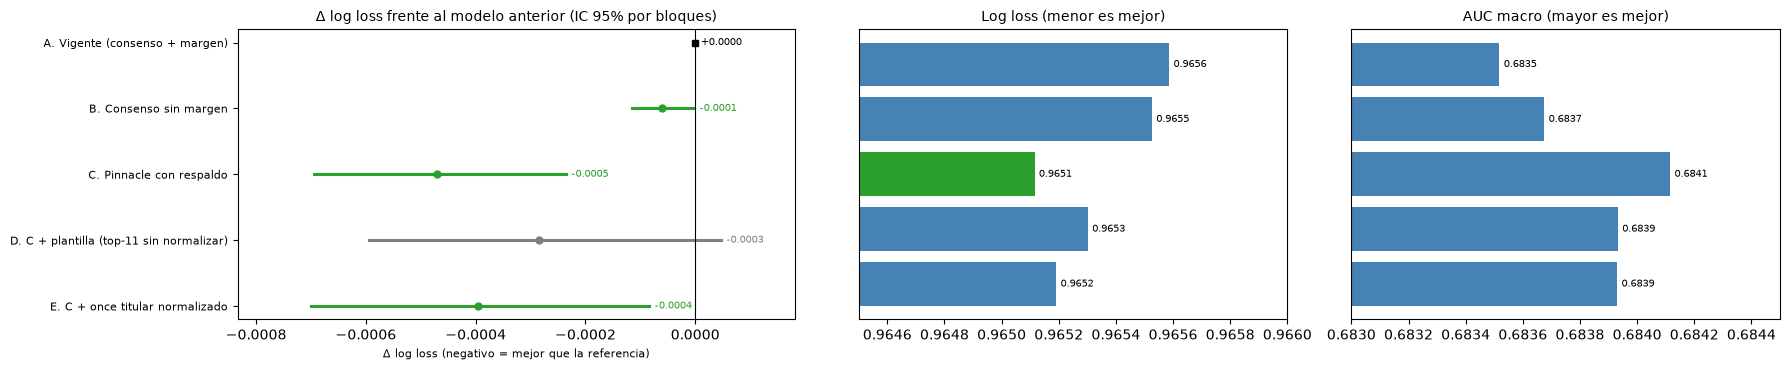


Mejor por log loss: C. Pinnacle con respaldo | cumple la regla (IC excluye 0 y >= 6/8 folds): True
MODELO FINAL -> C. Pinnacle con respaldo ['REF_logit', 'REF_pD']


In [3]:
CAND = {'A. Vigente (consenso + margen)': ['MKT_logit', 'MKT_pD', 'MKT_margin'],
        'B. Consenso sin margen': ['MKT_logit', 'MKT_pD'],
        'C. Pinnacle con respaldo': ['REF_logit', 'REF_pD'],
        'D. C + plantilla (top-11 sin normalizar)': ['REF_logit', 'REF_pD', 'DIF_sq_top11'],
        'E. C + once titular normalizado': ['REF_logit', 'REF_pD', 'XIz_DIF']}
PC = {k: cv_proba(lr(0.05), df[v].to_numpy(float)) for k, v in CAND.items()}
LC = {k: loss_vec(p) for k, p in PC.items()}
A_ = 'A. Vigente (consenso + margen)'
filas = []
for k in CAND:
    c = comparar(LC[k], LC[A_]) if k != A_ else dict(delta=0.0, lo=np.nan, hi=np.nan, folds='-', p=np.nan)
    filas.append(dict(candidato=k, log_loss=np.nanmean(LC[k][EV]), rps=rps(PC[k][EV], y[EV]), AUC_macro=np.mean(aucs(PC[k][EV], y[EV])), delta_vs_A=c['delta'],
                      IC=f"[{c['lo']:+.4f}, {c['hi']:+.4f}]" if k != A_ else '-', folds_mejora=c['folds']))
tc = pd.DataFrame(filas).set_index('candidato')
cA = {k: (comparar(LC[k], LC[A_]) if k != A_ else dict(delta=0.0, lo=0.0, hi=0.0)) for k in CAND}
fig, axs = plt.subplots(1, 3, figsize=(18, 3.8), gridspec_kw={'width_ratios': [1.3, 1, 1]})
forest(axs[0], list(CAND), [cA[k]['delta'] for k in CAND], [cA[k]['lo'] for k in CAND], [cA[k]['hi'] for k in CAND], 'Δ log loss frente al modelo anterior (IC 95% por bloques)')
for ax, col, tit, lim in ((axs[1], 'log_loss', 'Log loss (menor es mejor)', (0.9645, 0.9660)), (axs[2], 'AUC_macro', 'AUC macro (mayor es mejor)', (0.6830, 0.6845))):
    ax.barh(range(len(tc))[::-1], tc[col], color=['tab:green' if k == tc[col].idxmin() and col == 'log_loss' else 'steelblue' for k in tc.index]); ax.set_xlim(*lim); ax.set_yticks([])
    for yi, v in zip(range(len(tc))[::-1], tc[col]): ax.text(v + (lim[1] - lim[0]) * 0.01, yi, f'{v:.4f}', va='center', fontsize=7)
    ax.set_title(tit, fontsize=10)
plt.tight_layout(); plt.show()
mejor = tc.log_loss.idxmin()
c = comparar(LC[mejor], LC[A_]); acepta = (mejor != A_) and (c['hi'] < 0) and (int(c['folds'].split('/')[0]) >= 6)
FINAL = mejor if acepta else 'B. Consenso sin margen'
FINAL_COLS = CAND[FINAL]
print(f"\nMejor por log loss: {mejor} | cumple la regla (IC excluye 0 y >= 6/8 folds): {acepta}")
print('MODELO FINAL ->', FINAL, FINAL_COLS)

**Qué encontramos.**

| Candidato | Log loss | AUC macro | Δ vs. A | IC 95% (bloques) | Folds |
|---|---|---|---|---|---|
| A. Vigente (consenso + margen) | 0.9656 | 0.6835 | — | — | — |
| B. Consenso sin margen | 0.9655 | 0.6837 | −0.0001 | [−0.0001, −0.0000] | 6/8 |
| **C. Pinnacle con respaldo** | **0.9651** | **0.6841** | **−0.0005** | [−0.0007, −0.0002] | 7/8 |
| D. C + plantilla (top-11 sin normalizar) | 0.9653 | 0.6839 | −0.0003 | [−0.0006, +0.0000] | 6/8 |
| E. C + once titular normalizado | 0.9652 | 0.6839 | −0.0004 | [−0.0007, −0.0001] | 7/8 |

El mejor es C y **cumple la regla** definida de antemano (IC que excluye 0 y mejora en 7 de 8 temporadas). Añadir la plantilla, sea el top-11 sin normalizar (D, 0.9653) o el **once titular normalizado** (E, 0.9652), empeora respecto a C (0.9651): una vez más, no aporta nada sobre el precio.

**Qué significa para nuestro caso.** El modelo final queda con **solo dos variables**: `REF_logit` y `REF_pD`. La mejora sobre el modelo anterior es real pero **pequeña** (0.0005 de log loss, un 0.05%): refina el precio, no descubre información nueva. Que la plantilla siga sin aportar confirma, con el mejor precio disponible, el resultado central del proyecto: lo que sabemos del equipo ya está en la cuota.

## Paso 2b — ¿Mejora el modelo con una corrección distinta por liga?

**Qué vamos a hacer.** Hasta ahora el modelo aprende **una sola** transformación del precio para las nueve ligas. Probar dos formas de dejar que cada liga tenga su propio desplazamiento (intercepto), partiendo del candidato C (Pinnacle con respaldo):

| Candidato | Qué es |
|---|---|
| **C** (el actual) | `REF_logit`, `REF_pD` |
| **F. C + liga (indicadoras)** | C más 8 columnas 0/1, una por liga menos la de referencia; el modelo aprende un coeficiente por liga |
| **G. C + liga con encogimiento** | igual que F, pero con las indicadoras escaladas a la mitad de ese tamaño: la regularización las penaliza más y solo se desvía de la corrección común si hay evidencia clara (*shrinkage*) |

**Regla de elección (fijada antes de ver los resultados).** Un candidato con liga reemplaza a C solo si su diferencia de log loss frente a C tiene un IC por bloques que excluye 0 **y** mejora en al menos 6 de 8 temporadas.

**Por qué.** En el Paso 4 se verá que la mejora sobre el mercado viene casi toda de Portugal y Turquía; si esas ligas tienen un sesgo propio y estable, un intercepto por liga lo captura. Todo se estima solo con partidos anteriores a cada temporada.

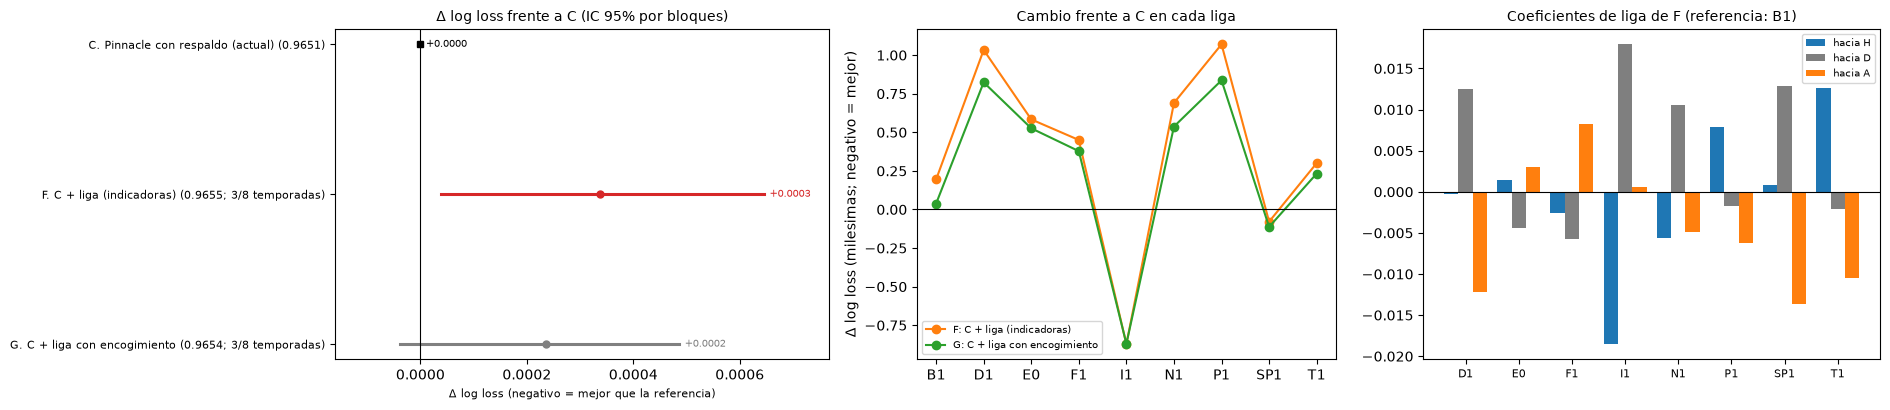

cumplen la regla (IC excluye 0 y >= 6/8 temporadas): ninguno | MODELO FINAL se mantiene en: C. Pinnacle con respaldo


In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer
liga_d = pd.get_dummies(df['Div'], drop_first=True).astype(float)
XL = np.c_[df[['REF_logit', 'REF_pD']].to_numpy(float), liga_d.to_numpy()]
def lr_liga(esc):
    ct = ColumnTransformer([('precio', StandardScaler(), [0, 1]), ('liga', FunctionTransformer(lambda Z, e=esc: Z * e), list(range(2, XL.shape[1])))])
    return lambda: make_pipeline(ct, LogisticRegression(C=0.05, max_iter=5000))
LIGAS = {'C. Pinnacle con respaldo (actual)': (PC['C. Pinnacle con respaldo'], None), 'F. C + liga (indicadoras)': (cv_proba(lr_liga(3.0), XL), 3.0), 'G. C + liga con encogimiento': (cv_proba(lr_liga(0.5), XL), 0.5)}
LL = {k: loss_vec(v[0]) for k, v in LIGAS.items()}; refC = 'C. Pinnacle con respaldo (actual)'
cl_liga = {k: (comparar(LL[k], LL[refC]) if k != refC else dict(delta=0.0, lo=0.0, hi=0.0, folds='-', p=np.nan)) for k in LIGAS}
liga_arr = df['Div'].to_numpy(); ligas_ = sorted(np.unique(liga_arr))
fig, axs = plt.subplots(1, 3, figsize=(19, 4.2), gridspec_kw={'width_ratios': [1.3, 1.1, 1.2]})
forest(axs[0], [f"{k} ({np.nanmean(LL[k][EV]):.4f}; {cl_liga[k]['folds']} temporadas)" if k != refC else f"{k} ({np.nanmean(LL[k][EV]):.4f})" for k in LIGAS], [cl_liga[k]['delta'] for k in LIGAS], [cl_liga[k]['lo'] for k in LIGAS], [cl_liga[k]['hi'] for k in LIGAS], 'Δ log loss frente a C (IC 95% por bloques)')
for nm_, col_ in (('F. C + liga (indicadoras)', 'tab:orange'), ('G. C + liga con encogimiento', 'tab:green')):
    dl = [np.nanmean((LL[nm_] - LL[refC])[(liga_arr == l) & EV]) * 1000 for l in ligas_]
    axs[1].plot(ligas_, dl, marker='o', color=col_, label=nm_.split('. ')[0] + ': ' + nm_.split('. ')[1])
axs[1].axhline(0, color='k', lw=0.8); axs[1].set_ylabel('Δ log loss (milesimas; negativo = mejor)'); axs[1].legend(fontsize=7); axs[1].set_title('Cambio frente a C en cada liga', fontsize=10)
mF = lr_liga(3.0)().fit(XL[seas < 2526], y[seas < 2526]); coefl = mF[-1].coef_[:, 2:]
for k_, (lab_, col_) in enumerate((('hacia H', 'tab:blue'), ('hacia D', 'tab:gray'), ('hacia A', 'tab:orange'))): axs[2].bar(np.arange(coefl.shape[1]) + (k_ - 1) * 0.27, coefl[k_], 0.27, color=col_, label=lab_)
axs[2].axhline(0, color='k', lw=0.8); axs[2].set_xticks(range(coefl.shape[1])); axs[2].set_xticklabels(list(liga_d.columns), fontsize=8); axs[2].legend(fontsize=7); axs[2].set_title(f'Coeficientes de liga de F (referencia: {sorted(np.unique(liga_arr))[0]})', fontsize=10)
plt.tight_layout(); plt.show()
ACEPTA_LIGA = [k for k in ('F. C + liga (indicadoras)', 'G. C + liga con encogimiento') if cl_liga[k]['hi'] < 0 and int(cl_liga[k]['folds'].split('/')[0]) >= 6]
print('cumplen la regla (IC excluye 0 y >= 6/8 temporadas):', ACEPTA_LIGA or 'ninguno', '| MODELO FINAL se mantiene en:', FINAL if not ACEPTA_LIGA else '(revisar)')

**Qué encontramos.** Ninguna de las dos formas de corregir por liga mejora a C; las dos lo empeoran un poco.

| Candidato | Log loss | Δ vs. C | IC 95% (bloques) | Temporadas en que mejora |
|---|---|---|---|---|
| **C. Pinnacle con respaldo (actual)** | **0.9651** | — | — | — |
| F. C + liga (indicadoras) | 0.9655 | +0.0003 | [+0.0000, +0.0007] | 3/8 |
| G. C + liga con encogimiento | 0.9654 | +0.0002 | [−0.0000, +0.0005] | 3/8 |

- **Los coeficientes de liga son minúsculos** (como máximo ±0.02 en el logit, con variables en escala de desviación estándar): el modelo casi no encuentra un desplazamiento propio de ninguna liga.
- **El efecto no es estable entre temporadas:** F mejora a C en 3 de 8 temporadas y empeora claramente en las primeras (+0.0018 en 2018/19 y +0.0011 en 2019/20). Por liga, solo Italia mejora (−0.0009); Portugal y Turquía, donde el modelo final sí ganaba al mercado, **empeoran** (+0.0011 y +0.0003).
- Ningún candidato cumple la regla fijada antes de ver los resultados (IC que excluye 0 con mejora, y al menos 6 de 8 temporadas).

**Qué significa para nuestro caso.** La ventaja del modelo final en Portugal y Turquía **no viene de un sesgo fijo de esas ligas**: si lo fuera, un intercepto por liga lo capturaría y lo vemos al revés. Lo más probable es que venga de cómo se corrige la relación entre el precio y el resultado (la pendiente de calibración), que en esas ligas se aleja más de 1, y esa corrección ya la hace el modelo común. Añadir la etiqueta de liga solo agrega parámetros que se ajustan al ruido, sobre todo en las primeras temporadas, que entrenan con pocos partidos por liga.

**Decisión.** El modelo final se mantiene en C (dos variables, sin etiqueta de liga). Queda documentado que se probó la corrección por liga y no ayuda.

## Paso 3 — Regularización con validación temporal anidada

**Qué vamos a hacer.** Elegir `C` de la regresión logística para las variables del modelo final: para cada temporada de evaluación `s`, se prueba una rejilla amplia (`10⁻⁴ … 100`) entrenando con lo anterior a `t` y evaluando en `t`, para `t` ∈ {`s−2`, `s−1`}; se elige la `C` de menor log loss (desempate: menor `C`, más regularización). La `C` definitiva para el modelo que se guardará se elige igual con las **dos últimas temporadas** (2024/25 y 2025/26).

**Por qué.** `05_hiperparametros` mostró que fijar `C` con una sola ventana no sesga el resultado; aquí se repite para el modelo final y se mide cuánto depende la evaluación de esa elección.

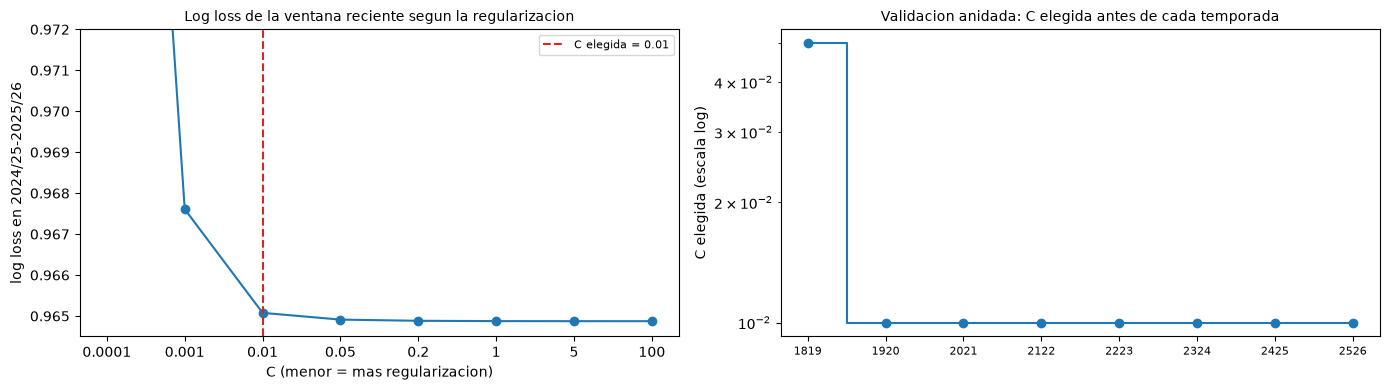

C definitiva: 0.01 | log loss 8 folds: C anidada 0.9652 | C fija 0.9652


In [5]:
GRID_C = (1e-4, 1e-3, 0.01, 0.05, 0.2, 1, 5, 100)
Xf = df[FINAL_COLS].to_numpy(float)
def ll_t(C, t):
    m = lr(C)().fit(Xf[seas < t], y[seas < t]); return log_loss(y[seas == t], m.predict_proba(Xf[seas == t]), labels=[0, 1, 2])
def elegir_C(inner):
    sc = {C: np.mean([ll_t(C, t) for t in inner]) for C in GRID_C}; mn = min(sc.values()); return min(C for C, v in sc.items() if v <= mn + 0.0005), sc
P_fin = np.full((len(y), 3), np.nan); elegidas = []
for s in FOLDS:
    i = TEMP.index(s); Cs, _ = elegir_C([TEMP[i - 2], TEMP[i - 1]]); elegidas.append(Cs)
    P_fin[seas == s] = lr(Cs)().fit(Xf[seas < s], y[seas < s]).predict_proba(Xf[seas == s])
C_FINAL, sc_final = elegir_C(TEMP[-2:])
P_fija = cv_proba(lr(C_FINAL), Xf)
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
axs[0].plot([str(c) for c in GRID_C], [sc_final[c] for c in GRID_C], marker='o', color='tab:blue'); axs[0].axvline(str(C_FINAL), color='tab:red', ls='--', label=f'C elegida = {C_FINAL}'); axs[0].set_ylim(0.9645, 0.972)
axs[0].set_xlabel('C (menor = mas regularizacion)'); axs[0].set_ylabel('log loss en 2024/25-2025/26'); axs[0].set_title('Log loss de la ventana reciente segun la regularizacion', fontsize=10); axs[0].legend(fontsize=8)
axs[1].step(range(len(FOLDS)), elegidas, where='mid', marker='o', color='tab:blue'); axs[1].set_yscale('log'); axs[1].set_xticks(range(len(FOLDS))); axs[1].set_xticklabels([int(s_) for s_ in FOLDS], fontsize=8); axs[1].set_ylabel('C elegida (escala log)'); axs[1].set_title('Validacion anidada: C elegida antes de cada temporada', fontsize=10)
plt.tight_layout(); plt.show()
print('C definitiva:', C_FINAL, f'| log loss 8 folds: C anidada {np.nanmean(loss_vec(P_fin)[EV]):.4f} | C fija {np.nanmean(loss_vec(P_fija)[EV]):.4f}')

**Qué encontramos.**

- La `C` elegida por validación anidada es **0.01 en 7 de 8 folds** (0.05 en el primero). Para la ventana más reciente (2024/25–2025/26) los log loss son prácticamente iguales entre `C = 0.05` y `C = 100` (0.9649), y la elección se queda con la más regularizada (0.01) por la regla de simplicidad.
- Con la `C` anidada o con `C = 0.01` fija, el log loss es el mismo: **0.9652**.

**Qué significa para nuestro caso.** Con dos variables, la regularización casi no importa (la superficie es plana entre 0.05 y 100). Usamos `C = 0.01`. El costo es mínimo pero visible en la calibración (pendiente ≈ 1.06 en vez de 1.03; ver Paso 4), porque una regularización mayor encoge los coeficientes. Si en el futuro la calibración fuera lo más importante, `C = 0.05` sería igual de defendible.

## Paso 4 — Evaluación completa fuera de muestra

**Qué vamos a hacer.** Con las predicciones de los 8 folds del modelo final (`C` elegida por validación anidada), calcular todas las métricas y compararlas con cuatro referencias sobre las mismas filas: el **prior**, el **mercado crudo** (consenso proporcional), **Pinnacle cruda** (cuando está) y la **LR vigente** (candidato A). Contrastes pareados con IC por bloques y corrección de Benjamini–Hochberg.

**Por qué.** Es la tabla que irá al informe: debe permitir decir, con intervalos, si el modelo final mejora o no a lo que ya teníamos y al mercado.

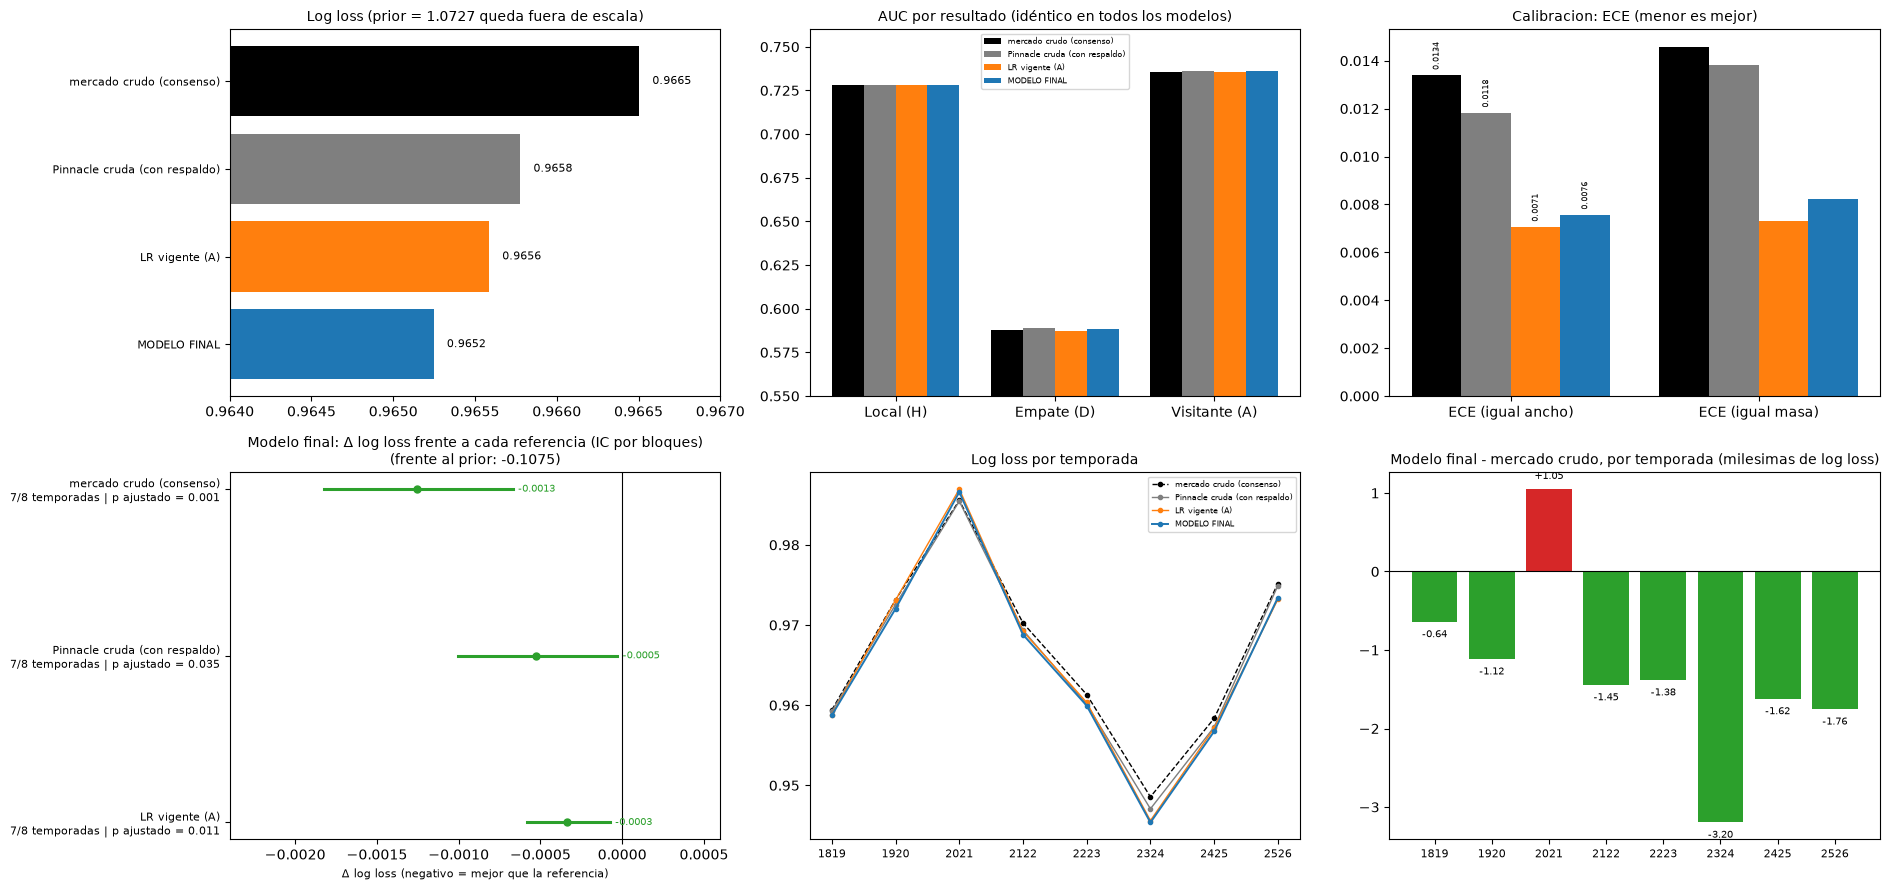

pendientes de calibracion (H/D/A): {'mercado crudo (consenso)': [1.115, 1.285, 1.133], 'Pinnacle cruda (con respaldo)': [1.098, 1.23, 1.118], 'LR vigente (A)': [1.035, 1.036, 1.023], 'MODELO FINAL': [1.064, 1.063, 1.057]}


In [6]:
oo = pd.read_csv(DATA + 'modelos_oof.csv'); idx = oo['idx'].to_numpy()
Pmk = odds[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy()
Ppin = np.where(psok[:, None], pp, Pmk)                       # Pinnacle cruda con respaldo
prior = np.full((len(y), 3), np.nan)
for s in FOLDS: prior[seas == s] = np.bincount(y[seas < s], minlength=3) / (seas < s).sum()
REFS = {'prior': prior, 'mercado crudo (consenso)': np.where(EV[:, None], Pmk, np.nan), 'Pinnacle cruda (con respaldo)': np.where(EV[:, None], Ppin, np.nan),
        'LR vigente (A)': PC[A_], 'MODELO FINAL': P_fin}
filas = []
for k, Pm in REFS.items():
    a = aucs(Pm[EV], y[EV]); pr = Pm[EV]
    filas.append(dict(modelo=k, log_loss=log_loss(y[EV], pr, labels=[0, 1, 2]), RPS=rps(pr, y[EV]), Brier=brier(pr, y[EV]), acc=accuracy_score(y[EV], pr.argmax(1)),
                      bal_acc=balanced_accuracy_score(y[EV], pr.argmax(1)), AUC_H=a[0], AUC_D=a[1], AUC_A=a[2], AUC_macro=np.mean(a),
                      ECE_ancho=np.mean([ece_w(pr[:, j], y[EV] == j) for j in range(3)]), ECE_masa=np.mean([ece_q(pr[:, j], y[EV] == j) for j in range(3)]),
                      pend_H=pend(pr[:, 0], y[EV] == 0), pend_D=pend(pr[:, 1], y[EV] == 1), pend_A=pend(pr[:, 2], y[EV] == 2)))
met = pd.DataFrame(filas).set_index('modelo')
LF = loss_vec(P_fin); filas = []
for k in ('mercado crudo (consenso)', 'Pinnacle cruda (con respaldo)', 'LR vigente (A)', 'prior'):
    c = comparar(LF, loss_vec(REFS[k])); filas.append(dict(vs=k, delta_ll=c['delta'], lo=c['lo'], hi=c['hi'], folds_mejora=c['folds'], p=c['p']))
cmp_ = pd.DataFrame(filas); cmp_['p_BH'] = bh(cmp_.p.values)
por_fold = pd.DataFrame({k: [log_loss(y[seas == s], REFS[k][seas == s], labels=[0, 1, 2]) for s in FOLDS] for k in REFS}, index=[int(s) for s in FOLDS])
ref_n = [k for k in REFS if k != 'prior']; cl = {'mercado crudo (consenso)': 'black', 'Pinnacle cruda (con respaldo)': 'tab:gray', 'LR vigente (A)': 'tab:orange', 'MODELO FINAL': 'tab:blue'}
fig, axs = plt.subplots(2, 3, figsize=(19, 9))
axs[0, 0].barh(range(len(ref_n))[::-1], met.loc[ref_n, 'log_loss'], color=[cl[k] for k in ref_n]); axs[0, 0].set_xlim(0.9640, 0.9670); axs[0, 0].set_yticks(range(len(ref_n))[::-1]); axs[0, 0].set_yticklabels(ref_n, fontsize=8)
for yi, v in zip(range(len(ref_n))[::-1], met.loc[ref_n, 'log_loss']): axs[0, 0].text(v + 0.00008, yi, f'{v:.4f}', va='center', fontsize=8)
axs[0, 0].set_title('Log loss (prior = 1.0727 queda fuera de escala)', fontsize=10)
xs = np.arange(3); w = 0.2
for k, n in enumerate(ref_n): axs[0, 1].bar(xs + (k - 1.5) * w, met.loc[n, ['AUC_H', 'AUC_D', 'AUC_A']], w, color=cl[n], label=n)
axs[0, 1].set_xticks(xs); axs[0, 1].set_xticklabels(['Local (H)', 'Empate (D)', 'Visitante (A)']); axs[0, 1].set_ylim(0.55, 0.76); axs[0, 1].legend(fontsize=6); axs[0, 1].set_title('AUC por resultado (idéntico en todos los modelos)', fontsize=10)
for k, n in enumerate(ref_n): axs[0, 2].bar(np.arange(2) + (k - 1.5) * w, met.loc[n, ['ECE_ancho', 'ECE_masa']], w, color=cl[n])
axs[0, 2].set_xticks([0, 1]); axs[0, 2].set_xticklabels(['ECE (igual ancho)', 'ECE (igual masa)']); axs[0, 2].set_title('Calibracion: ECE (menor es mejor)', fontsize=10)
for k, n in enumerate(ref_n): axs[0, 2].text(np.arange(2)[0] + (k - 1.5) * w, met.loc[n, 'ECE_ancho'] + 0.0003, f"{met.loc[n, 'ECE_ancho']:.4f}", ha='center', fontsize=6, rotation=90)
c3 = cmp_[cmp_.vs != 'prior']
forest(axs[1, 0], [f"{r.vs}\n{r.folds_mejora} temporadas | p ajustado = {r.p_BH:.3f}" for r in c3.itertuples()], c3.delta_ll.to_numpy(), c3.lo.to_numpy(), c3.hi.to_numpy(), f"Modelo final: Δ log loss frente a cada referencia (IC por bloques)\n(frente al prior: {cmp_[cmp_.vs == 'prior'].delta_ll.iloc[0]:+.4f})")
axs[1, 0].set_xlim(-0.0024, 0.0006)
for k in ref_n: axs[1, 1].plot(range(len(FOLDS)), por_fold[k], marker='o', ms=3, color=cl[k], lw=1.4 if k == 'MODELO FINAL' else 1, ls='--' if k.startswith('mercado') else '-', label=k)
axs[1, 1].set_xticks(range(len(FOLDS))); axs[1, 1].set_xticklabels(por_fold.index, fontsize=8); axs[1, 1].legend(fontsize=6); axs[1, 1].set_title('Log loss por temporada', fontsize=10)
dm = (por_fold['MODELO FINAL'] - por_fold['mercado crudo (consenso)']) * 1000
axs[1, 2].bar(range(len(FOLDS)), dm, color=['tab:green' if v < 0 else 'tab:red' for v in dm]); axs[1, 2].axhline(0, color='k', lw=0.8); axs[1, 2].set_xticks(range(len(FOLDS))); axs[1, 2].set_xticklabels(por_fold.index, fontsize=8)
for x_, v in enumerate(dm): axs[1, 2].text(x_, v + (0.1 if v >= 0 else -0.1), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)
axs[1, 2].set_title('Modelo final - mercado crudo, por temporada (milesimas de log loss)', fontsize=10)
plt.tight_layout(); plt.show()
print('pendientes de calibracion (H/D/A):', {k: [round(float(met.loc[k, c]), 3) for c in ('pend_H', 'pend_D', 'pend_A')] for k in ref_n})
pd.DataFrame(np.c_[np.where(EV)[0], seas[EV], y[EV], P_fin[EV]], columns=['idx', 'Season', 'y', 'P_H', 'P_D', 'P_A']).to_csv(DATA + 'modelo_final_oof.csv', index=False)

**Qué encontramos.** Métricas sobre los 24,183 partidos de evaluación:

| | Prior | Mercado crudo | Pinnacle cruda | LR vigente | **Modelo final** |
|---|---|---|---|---|---|
| Log loss | 1.0727 | 0.9665 | 0.9658 | 0.9656 | **0.9652** |
| RPS | 0.2307 | 0.1948 | 0.1946 | 0.1946 | **0.1945** |
| Brier | 0.6491 | 0.5739 | 0.5735 | 0.5733 | **0.5732** |
| Balanced accuracy | 0.333 | 0.465 | 0.465 | 0.465 | **0.466** |
| AUC macro | 0.498 | 0.684 | 0.684 | 0.684 | **0.684** |
| ECE (ancho / masa) | 0.009 / 0.011 | 0.0134 / 0.0146 | 0.0118 / 0.0138 | 0.0071 / 0.0073 | 0.0076 / 0.0082 |

*Diferencia de log loss del modelo final (negativo = mejor), IC por bloques y Benjamini–Hochberg:*

| Frente a | Δ | IC 95% | Folds | *p* ajustado |
|---|---|---|---|---|
| Mercado crudo (consenso) | **−0.0013** | [−0.0018, −0.0007] | 7/8 | 0.001 |
| Pinnacle cruda | −0.0005 | [−0.0010, −0.0000] | 7/8 | 0.040 |
| LR vigente | −0.0003 | [−0.0006, −0.0001] | 7/8 | 0.011 |

Por temporada, el modelo final mejora al mercado crudo en 7 de 8 años; la excepción es 2020/21 (estadios vacíos), donde queda 0.0011 por debajo del mercado.

**Qué significa para nuestro caso.** El modelo final es el mejor de los que hemos probado en log loss, RPS y Brier, y es el único que supera al mercado crudo con un IC que excluye 0 **también tras corregir por pruebas múltiples** (−0.0013). Pero la magnitud es pequeña: la capacidad de ordenar partidos (AUC) es la misma que la del mercado (0.684) y su calibración es algo peor que la del modelo anterior (ECE 0.0076 frente a 0.0071). Es decir: **mejora la calibración del mercado, no su capacidad de ordenar los partidos**. Eso es coherente con una conclusión de mercado eficiente y es lo que conviene decir en el informe, sin exagerar.

## Paso 5 — Diagnóstico: ROC, calibración, desempeño por liga y coeficientes

**Qué vamos a hacer.**

1. **Curvas ROC** de los tres resultados del modelo final frente al mercado crudo.
2. **Diagramas de fiabilidad** (deciles de igual masa, intervalos de Wilson).
3. **Log loss por liga**, frente al mercado crudo con bootstrap por bloques y Benjamini–Hochberg sobre las 9 ligas.
4. **Coeficientes estandarizados** y su estabilidad entre temporadas (reajuste en cada fold).

**Por qué.** Un buen promedio puede esconder ligas donde el modelo pierde, tramos de probabilidad mal calibrados o coeficientes inestables. Las curvas ROC y de fiabilidad son las que pidió el profesor.

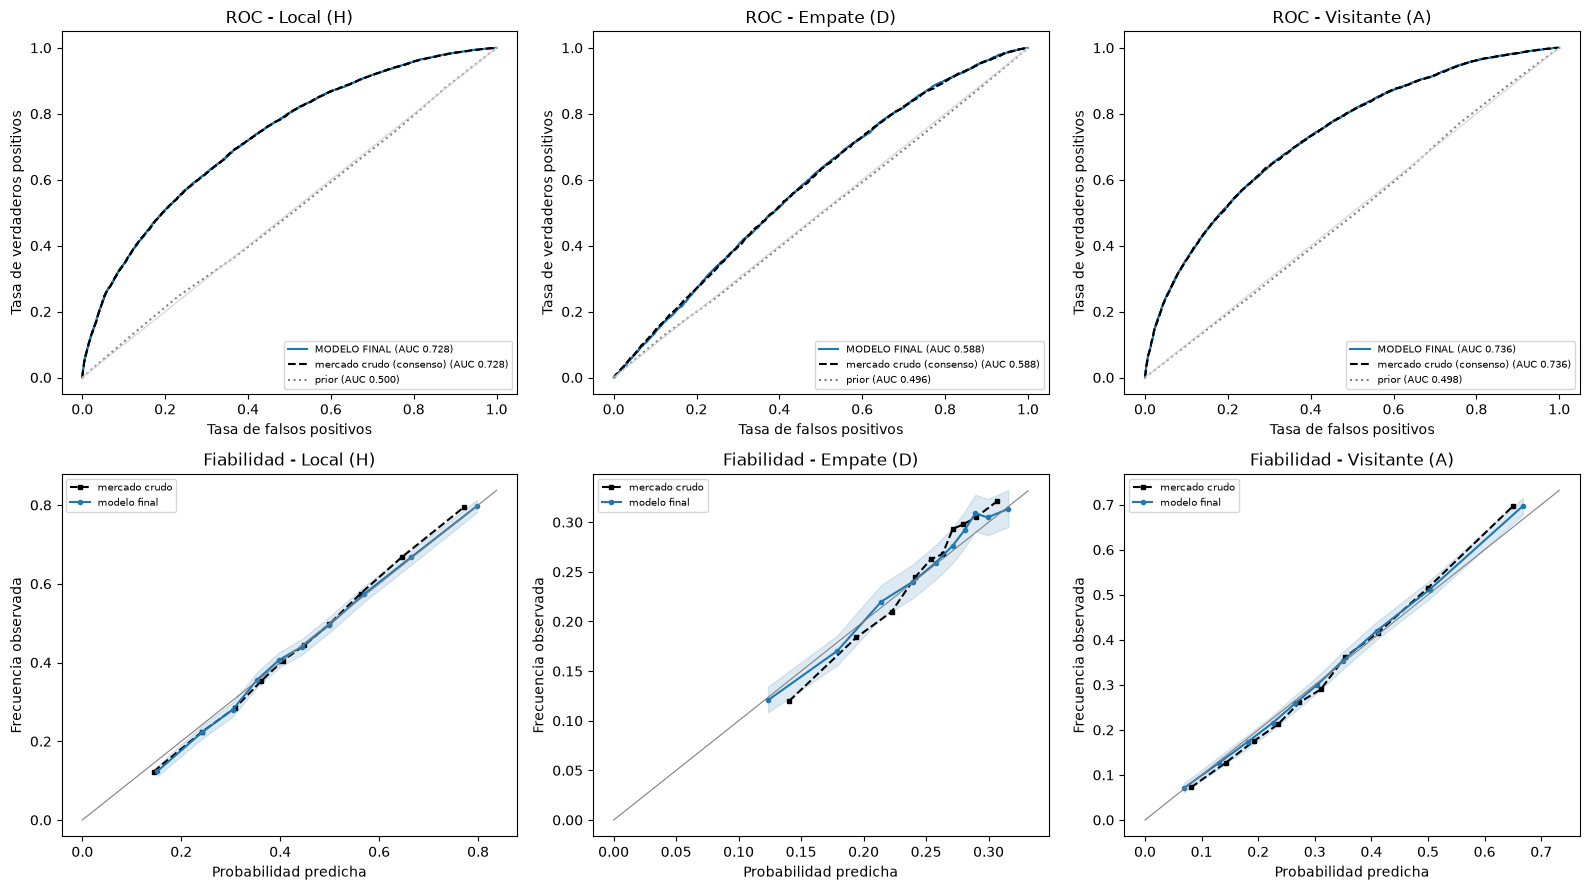

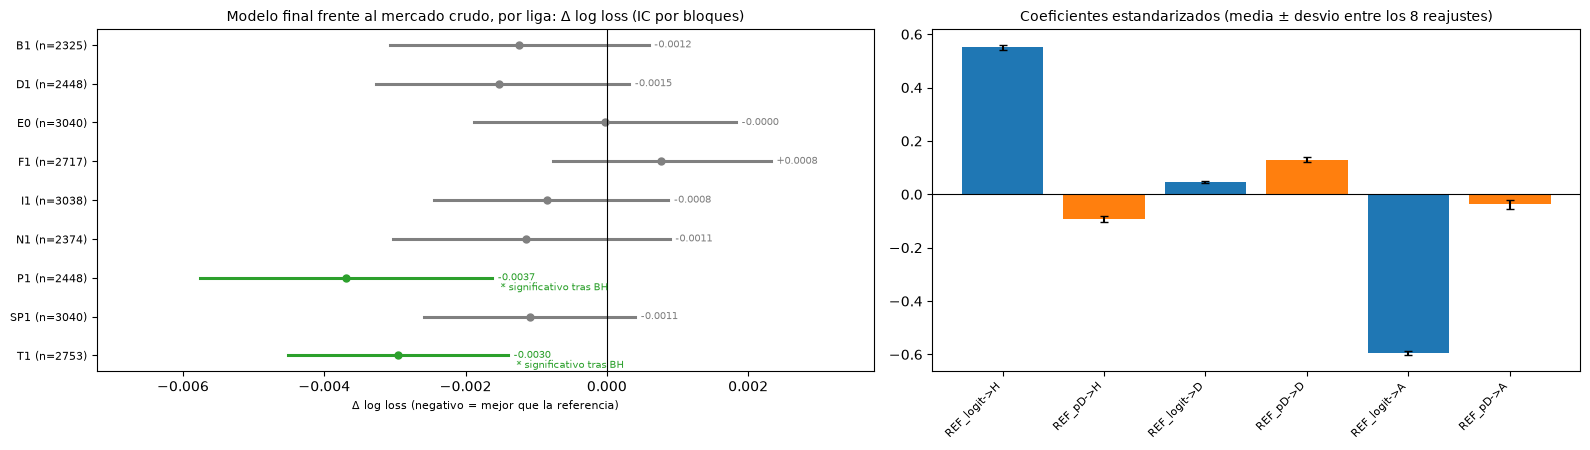

In [7]:
fig, axs = plt.subplots(2, 3, figsize=(16, 9)); nom = ['Local (H)', 'Empate (D)', 'Visitante (A)']
for j in range(3):
    ax = axs[0, j]
    for k, st in (('MODELO FINAL', ('tab:blue', '-')), ('mercado crudo (consenso)', ('k', '--')), ('prior', ('gray', ':'))):
        fpr, tpr, _ = roc_curve(y[EV] == j, REFS[k][EV][:, j]); ax.plot(fpr, tpr, color=st[0], ls=st[1], label=f'{k} (AUC {roc_auc_score(y[EV] == j, REFS[k][EV][:, j]):.3f})')
    ax.plot([0, 1], [0, 1], color='lightgray', lw=0.8); ax.set_title(f'ROC - {nom[j]}'); ax.set_xlabel('Tasa de falsos positivos'); ax.set_ylabel('Tasa de verdaderos positivos'); ax.legend(fontsize=7, loc='lower right')
    ax = axs[1, j]; p = P_fin[EV][:, j]; o = (y[EV] == j); b = pd.qcut(p, 10, labels=False, duplicates='drop')
    xs = np.array([p[b == k].mean() for k in np.unique(b)]); ys = np.array([o[b == k].mean() for k in np.unique(b)])
    ci = np.array([(lambda k_, n_: ((k_ / n_ + 1.96 ** 2 / (2 * n_)) / (1 + 1.96 ** 2 / n_) + np.array([-1, 1]) * 1.96 * np.sqrt((k_ / n_) * (1 - k_ / n_) / n_ + 1.96 ** 2 / (4 * n_ ** 2)) / (1 + 1.96 ** 2 / n_)))(o[b == k].sum(), (b == k).sum()) for k in np.unique(b)])
    pm = Pmk[EV][:, j]; bm = pd.qcut(pm, 10, labels=False, duplicates='drop')
    ax.plot([pm[bm == k].mean() for k in np.unique(bm)], [o[bm == k].mean() for k in np.unique(bm)], 'k--', marker='s', ms=3, label='mercado crudo')
    ax.plot(xs, ys, color='tab:blue', marker='o', ms=3, label='modelo final'); ax.fill_between(xs, ci[:, 0], ci[:, 1], color='tab:blue', alpha=0.15)
    lim = [0, max(xs.max(), ys.max()) * 1.05]; ax.plot(lim, lim, color='gray', lw=0.8); ax.set_title(f'Fiabilidad - {nom[j]}'); ax.set_xlabel('Probabilidad predicha'); ax.set_ylabel('Frecuencia observada'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# por liga
filas = []
Lmk = loss_vec(np.where(EV[:, None], Pmk, np.nan))
for d_ in sorted(np.unique(liga)):
    m = (liga == d_) & EV; c = comparar(LF, Lmk, mask=(liga == d_))
    filas.append(dict(liga=d_, n=int(m.sum()), ll_final=np.nanmean(LF[m]), ll_mercado=np.nanmean(Lmk[m]), delta=c['delta'], lo=c['lo'], hi=c['hi'], p=c['p']))
pl = pd.DataFrame(filas); pl['p_BH'] = bh(pl.p.values); pl['signif_5pct'] = pl.p_BH < 0.05
rows = []
for s_ in FOLDS:
    m = lr(C_FINAL)().fit(Xf[seas < s_], y[seas < s_]); co = m[-1].coef_
    rows.append(dict(fold=int(s_), **{f'{c}->{l}': co[k, i] for k, l in enumerate('HDA') for i, c in enumerate(FINAL_COLS)}))
cf = pd.DataFrame(rows).set_index('fold')
fig, axs = plt.subplots(1, 2, figsize=(16, 4.6), gridspec_kw={'width_ratios': [1.2, 1]})
forest(axs[0], [f"{r.liga} (n={r.n})" for r in pl.itertuples()], pl.delta.to_numpy(), pl.lo.to_numpy(), pl.hi.to_numpy(), 'Modelo final frente al mercado crudo, por liga: Δ log loss (IC por bloques)')
for yi, r in zip(np.arange(len(pl))[::-1], pl.itertuples()):
    if r.signif_5pct: axs[0].annotate('* significativo tras BH', (r.hi, yi), xytext=(6, -9), textcoords='offset points', fontsize=7, color='tab:green')
axs[1].bar(range(len(cf.columns)), cf.mean(), yerr=cf.std(), color=['tab:blue' if 'REF_logit' in c else 'tab:orange' for c in cf.columns], capsize=3)
axs[1].set_xticks(range(len(cf.columns))); axs[1].set_xticklabels(cf.columns, rotation=45, ha='right', fontsize=8); axs[1].axhline(0, color='k', lw=0.8)
axs[1].set_title('Coeficientes estandarizados (media ± desvio entre los 8 reajustes)', fontsize=10)
plt.tight_layout(); plt.show()

**Qué encontramos.**

- **Curvas ROC:** las del modelo final y del mercado crudo son indistinguibles en los tres resultados (AUC H 0.728, D 0.588, A 0.736); el prior queda sobre la diagonal.
- **Fiabilidad:** ambos siguen la diagonal en los deciles de los tres resultados; el mercado crudo se separa algo en los extremos (los favoritos de probabilidad alta ganan un poco más de lo que dice el precio) y el modelo final queda dentro de las bandas de Wilson.
- **Por liga:** la estimación puntual es mejor que el mercado en 8 de 9 ligas (en Inglaterra ≈ 0), pero **solo es significativo en Portugal (−0.0037) y Turquía (−0.0030)** tras Benjamini–Hochberg (*p* = 0.0045). En Francia el signo es contrario (+0.0008, no significativo).
- **Coeficientes:** muy estables entre temporadas (desvío ≤ 0.016 sobre coeficientes de ±0.6): +0.55 de `REF_logit` hacia local y −0.60 hacia visitante, y un efecto pequeño de `REF_pD` sobre el empate.

**Qué significa para nuestro caso.** El modelo es **interpretable y estable**: casi todo lo que hace es leer el precio (si el logit local–visitante sube una desviación estándar, la probabilidad de local sube y la de visitante baja) y corregirlo un poco en los extremos. La mejora no es uniforme: viene de ligas donde el mercado es menos eficiente (Portugal y Turquía). Una hipótesis razonable es que son mercados menos líquidos, pero no la probamos y, con nueve ligas y un solo periodo, no es una conclusión firme. No hay señal de deterioro entre temporadas, así que el modelo puede reutilizarse sin reentrenar cada año.

## Paso 6 — Backtest de apuestas

**Qué vamos a hacer.** Convertir las probabilidades fuera de muestra en apuestas de una unidad al resultado de mayor valor esperado `EV = P · cuota − 1` si `EV > τ`, con cuotas de **apertura** de Bet365 y Pinnacle. Mismo diseño que `06_mercado` (Paso 7): `τ ∈ {0, 0.02, …, 0.08}` se elige con los 4 primeros folds (2018/19–2021/22), con al menos 200 apuestas, y se **reporta** en los 4 últimos (2022/23–2025/26). Intervalos por *bootstrap* de bloques.

**Por qué.** Cierra el proyecto con una cifra en dinero. Si el modelo no tiene información que el mercado no tenga, el ROI esperado es ≈ −margen de la casa.

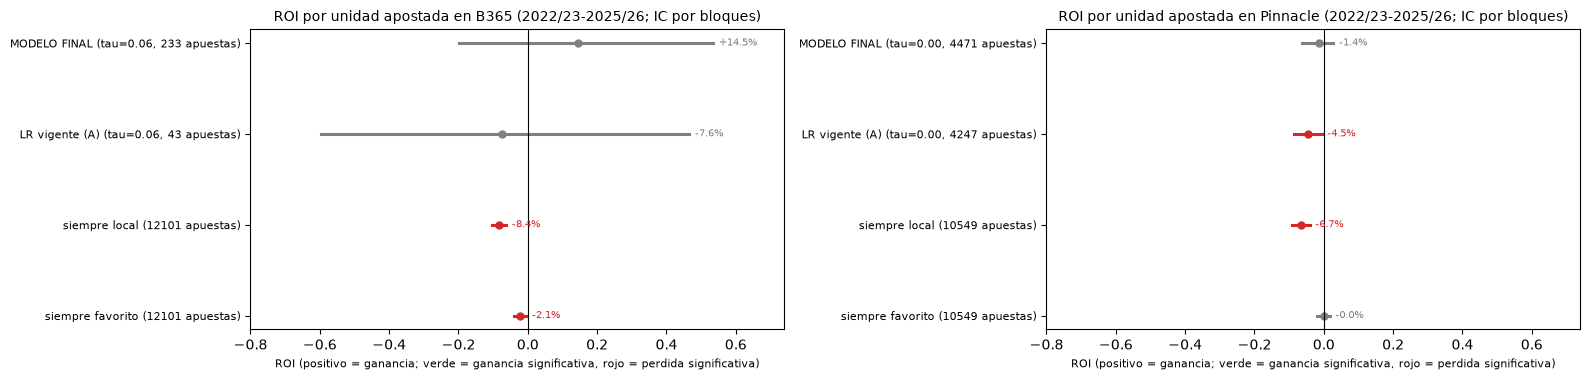

In [8]:
O_B = odds[['B365H', 'B365D', 'B365A']].to_numpy(float)
O_P = np.where(psok[:, None], PS, np.nan)
def apuestas(P, O, tau, mask):
    ev = P * O - 1; ev = np.where(np.isnan(ev), -np.inf, ev); j = ev.argmax(1); evm = ev[np.arange(len(ev)), j]
    bet = mask & (evm > tau) & ~np.isnan(O[np.arange(len(O)), j]); pnl = np.where(y == j, O[np.arange(len(O)), j] - 1, -1.0); return bet, pnl
def roi_ic(bet, pnl, B=1000):
    ix = np.where(bet)[0]
    if len(ix) < 30: return np.nan, np.nan, np.nan
    cod = pd.factorize(bloque[ix])[0]; K = cod.max() + 1; sm = np.bincount(cod, weights=pnl[ix], minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    s_ = rng.integers(0, K, (B, K)); bs = sm[s_].sum(1) / np.maximum(cn[s_].sum(1), 1); return pnl[ix].mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)
primeros, ultimos = np.isin(seas, FOLDS[:4]), np.isin(seas, FOLDS[4:])
filas = []
for casa, O in (('B365', O_B), ('Pinnacle', O_P)):
    for modelo, Pm in (('MODELO FINAL', P_fin), ('LR vigente (A)', PC[A_])):
        cand = []
        for tau in (0.0, 0.02, 0.04, 0.06, 0.08):
            b1, p1 = apuestas(Pm, O, tau, primeros)
            if b1.sum() >= 200: cand.append((p1[b1].mean(), tau))
        tau = max(cand)[1] if cand else 0.0
        b2, p2 = apuestas(Pm, O, tau, ultimos); r, lo, hi = roi_ic(b2, p2)
        filas.append(dict(casa=casa, modelo=modelo, tau_elegido=tau, apuestas_test=int(b2.sum()), ROI_test=r, lo=lo, hi=hi))
    # referencias
    fav = np.argmin(np.nan_to_num(O, nan=99), axis=1)
    for nom_r, j in (('siempre local', np.zeros(len(y), int)), ('siempre favorito', fav)):
        ok = ultimos & ~np.isnan(O).any(1); pnl = np.where(y == j, O[np.arange(len(O)), j] - 1, -1.0); r, lo, hi = roi_ic(ok, pnl)
        filas.append(dict(casa=casa, modelo=nom_r, tau_elegido=np.nan, apuestas_test=int(ok.sum()), ROI_test=r, lo=lo, hi=hi))
bt = pd.DataFrame(filas)
fig, axs = plt.subplots(1, 2, figsize=(16, 3.9), sharex=True)
for ax, casa in zip(axs, ('B365', 'Pinnacle')):
    sub_ = bt[bt.casa == casa]
    forest(ax, [f"{r.modelo} (tau={r.tau_elegido:.2f}, {r.apuestas_test} apuestas)" if r.tau_elegido == r.tau_elegido else f"{r.modelo} ({r.apuestas_test} apuestas)" for r in sub_.itertuples()], sub_.ROI_test.to_numpy(), sub_.lo.to_numpy(), sub_.hi.to_numpy(), f'ROI por unidad apostada en {casa} (2022/23-2025/26; IC por bloques)', xlabel='ROI (positivo = ganancia; verde = ganancia significativa, rojo = perdida significativa)', fmt='{:+.1%}', positivo_bueno=True)
plt.tight_layout(); plt.show()

**Qué encontramos.** `τ` elegido en 2018/19–2021/22 y resultados en 2022/23–2025/26:

| Casa | Modelo | `τ` | Apuestas | ROI | IC 95% (bloques) |
|---|---|---|---|---|---|
| B365 | **Modelo final** | 0.06 | 233 | +14.5% | [−20.3%, +55.2%] |
| B365 | LR vigente | 0.06 | 43 | −7.6% | [−64.9%, +50.0%] |
| B365 | siempre local | — | 12,101 | −8.4% | [−10.6%, −6.1%] |
| B365 | siempre favorito | — | 12,101 | −2.1% | [−3.7%, −0.4%] |
| Pinnacle | **Modelo final** | 0.00 | 4,471 | −1.4% | [−6.3%, +3.0%] |
| Pinnacle | LR vigente | 0.00 | 4,247 | −4.5% | [−8.9%, −0.1%] |
| Pinnacle | siempre local | — | 10,549 | −6.7% | [−9.6%, −4.2%] |
| Pinnacle | siempre favorito | — | 10,549 | −0.0% | [−1.7%, +1.7%] |

**Qué significa para nuestro caso.** El modelo final **pierde menos que el modelo anterior** (−1.4% frente a −4.5% en Pinnacle) y que las reglas ingenuas, y su ROI en Pinnacle no es distinguible de 0. El +14.5% con Bet365 es un resultado **engañoso**: solo 233 apuestas, un intervalo de ±38 puntos que incluye pérdidas grandes, y `τ` elegido entre cinco candidatos. **No lo presentaríamos como evidencia de rentabilidad**; lo correcto es decir que "no se detecta un retorno significativamente positivo", igual que en `06_mercado`. Con un margen medio de Pinnacle de 3.4% en estas temporadas y un ROI de −1.4%, el modelo recupera algo más de la mitad del margen, pero no lo supera.

## Paso 7 — Entrenamiento final, guardado y uso con cuotas nuevas

**Qué vamos a hacer.**

1. Entrenar el modelo con **todos** los partidos (2014/15–2025/26).
2. Guardarlo como `modelo_final.joblib` (objeto de scikit-learn) y como `modelo_final.json` (variables, medias y desvíos del escalado, coeficientes e intercepto), para poder usarlo sin scikit-learn.
3. Definir `predecir_1x2(...)`, que recibe cuotas decimales de apertura y devuelve `P(H), P(D), P(A)`.
4. **Verificar** que `predecir_1x2` reproduce exactamente las probabilidades del modelo de scikit-learn en 1,000 partidos, y mostrar un ejemplo.

**Por qué.** Un modelo que solo existe dentro de un cuaderno no sirve. La versión en JSON permite revisar los coeficientes, y la verificación evita que la función de uso y el modelo entrenado difieran en silencio.

diferencia maxima entre predecir_1x2 y el modelo de scikit-learn: 2.220446049250313e-16
Ejemplo (Pinnacle apertura 2.10 / 3.50 / 3.60): P(H)=0.452, P(D)=0.290, P(A)=0.258
Respaldo sin Pinnacle (B365 2.10/3.50/3.60 + WH 2.05/3.40/3.70): [0.455 0.291 0.254]


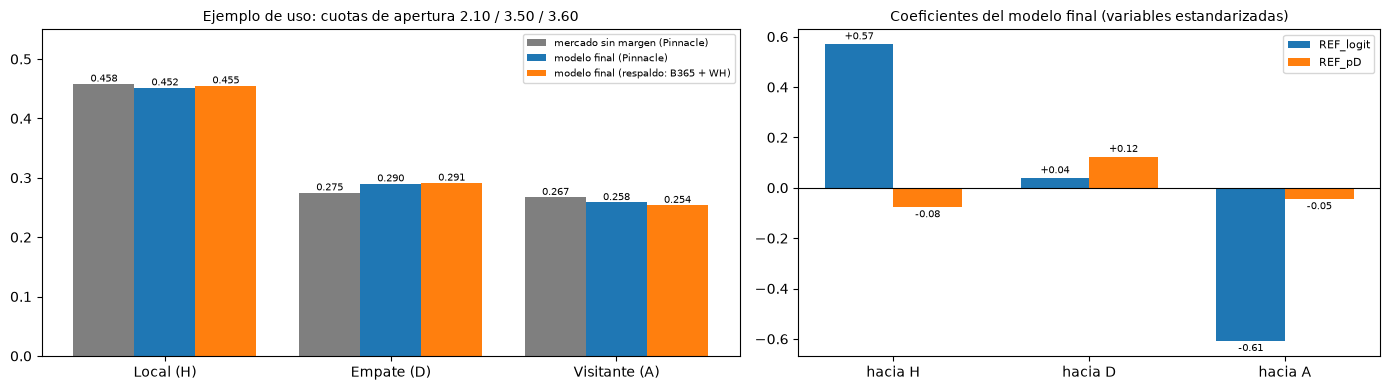

guardado: modelo_final.json, modelo_final.joblib, modelo_final_oof.csv en ../data/


In [9]:
modelo = lr(C_FINAL)().fit(Xf, y)
sc, lg_ = modelo[0], modelo[-1]
meta = dict(version='1.0', fecha_entrenamiento=str(pd.Timestamp.today().date()), partidos=int(len(y)), ultima_fecha=str(fechas.max().date()), temporadas=[int(TEMP[0]), int(TEMP[-1])],
            modelo='Regresion logistica multinomial estandarizada', variables=FINAL_COLS, C=float(C_FINAL), clases=['H', 'D', 'A'],
            media=sc.mean_.tolist(), escala=sc.scale_.tolist(), coef=lg_.coef_.tolist(), intercepto=lg_.intercept_.tolist(),
            nota='Variables: logit(pH/pA) y pD de las probabilidades implicitas normalizadas de la cuota de APERTURA de Pinnacle (respaldo: consenso de B365, BW, WH, PS). No incluir cuotas de cierre.')
json.dump(meta, open(DATA + 'modelo_final.json', 'w'), indent=1); joblib.dump(modelo, DATA + 'modelo_final.joblib')

def _probs(cuotas):
    inv = 1.0 / np.asarray(cuotas, float); return inv / inv.sum(axis=-1, keepdims=True)
def predecir_1x2(cuotas_pinnacle=None, cuotas_otras=None):
    """cuotas_pinnacle: (H, D, A) decimales de apertura; cuotas_otras: lista de (H, D, A) de otras casas (respaldo). Devuelve (P_H, P_D, P_A)."""
    if cuotas_pinnacle is not None and not np.isnan(np.asarray(cuotas_pinnacle, float)).any(): p = _probs(cuotas_pinnacle)
    elif cuotas_otras: p = np.mean([_probs(c) for c in cuotas_otras], axis=0)
    else: raise ValueError('hacen falta cuotas de Pinnacle o de otras casas')
    x = (np.array([np.log(p[0] / p[2]), p[1]]) - np.array(meta['media'])) / np.array(meta['escala'])
    z = np.array(meta['coef']) @ x + np.array(meta['intercepto']); e = np.exp(z - z.max()); return tuple(e / e.sum())

# verificacion: la funcion reproduce al modelo entrenado en 1,000 partidos
muestra = np.random.default_rng(1).choice(np.where(psok)[0], 1000, replace=False)
mio = np.array([predecir_1x2(cuotas_pinnacle=PS[i]) for i in muestra]); sk = modelo.predict_proba(df.loc[muestra, FINAL_COLS].to_numpy(float))
print('diferencia maxima entre predecir_1x2 y el modelo de scikit-learn:', float(np.abs(mio - sk).max()))
assert np.abs(mio - sk).max() < 1e-9
ej = predecir_1x2(cuotas_pinnacle=(2.10, 3.50, 3.60))
print('Ejemplo (Pinnacle apertura 2.10 / 3.50 / 3.60):', 'P(H)=%.3f, P(D)=%.3f, P(A)=%.3f' % ej)
print('Respaldo sin Pinnacle (B365 2.10/3.50/3.60 + WH 2.05/3.40/3.70):', np.round(predecir_1x2(cuotas_otras=[(2.10, 3.50, 3.60), (2.05, 3.40, 3.70)]), 3))
resp = predecir_1x2(cuotas_otras=[(2.10, 3.50, 3.60), (2.05, 3.40, 3.70)])
fig, axs = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={'width_ratios': [1.2, 1]})
xs = np.arange(3); w = 0.27; mk_ej = _probs((2.10, 3.50, 3.60))
axs[0].bar(xs - w, mk_ej, w, color='tab:gray', label='mercado sin margen (Pinnacle)'); axs[0].bar(xs, ej, w, color='tab:blue', label='modelo final (Pinnacle)'); axs[0].bar(xs + w, resp, w, color='tab:orange', label='modelo final (respaldo: B365 + WH)')
for x_, v in zip(np.r_[xs - w, xs, xs + w], list(mk_ej) + list(ej) + list(resp)): axs[0].text(x_, v + 0.004, f'{v:.3f}', ha='center', fontsize=7)
axs[0].set_xticks(xs); axs[0].set_xticklabels(['Local (H)', 'Empate (D)', 'Visitante (A)']); axs[0].set_ylim(0, 0.55); axs[0].legend(fontsize=7); axs[0].set_title('Ejemplo de uso: cuotas de apertura 2.10 / 3.50 / 3.60', fontsize=10)
co = pd.DataFrame(meta['coef'], index=['H', 'D', 'A'], columns=FINAL_COLS)
for k, c_ in enumerate(FINAL_COLS): axs[1].bar(xs + (k - 0.5) * 0.35, co[c_], 0.35, label=c_)
axs[1].axhline(0, color='k', lw=0.8); axs[1].set_xticks(xs); axs[1].set_xticklabels(['hacia H', 'hacia D', 'hacia A']); axs[1].legend(fontsize=8); axs[1].set_title('Coeficientes del modelo final (variables estandarizadas)', fontsize=10)
for k, c_ in enumerate(FINAL_COLS):
    for x_, v in zip(xs + (k - 0.5) * 0.35, co[c_]): axs[1].text(x_, v + (0.01 if v >= 0 else -0.01), f'{v:+.2f}', ha='center', va='bottom' if v >= 0 else 'top', fontsize=7)
plt.tight_layout(); plt.show()
print('guardado: modelo_final.json, modelo_final.joblib, modelo_final_oof.csv en', DATA)

**Qué encontramos.**

- El modelo se entrenó con **todos los partidos** (36,119; 2014/15–2025/26) y se guardó en `modelo_final.joblib` y `modelo_final.json` (variables, medias y desvíos, coeficientes e intercepto).
- `predecir_1x2` reproduce las probabilidades del modelo de scikit-learn con una diferencia máxima de **2·10⁻¹⁶** en 1,000 partidos: la función de uso y el modelo guardado son equivalentes.
- Ejemplo: con cuotas de apertura de Pinnacle 2.10 / 3.50 / 3.60, el modelo da **P(H) = 0.452, P(D) = 0.290, P(A) = 0.258**, frente a 0.458 / 0.275 / 0.267 del mercado sin margen: baja un poco al local y al visitante y sube el empate. Con el respaldo de otras casas da 0.455 / 0.291 / 0.254.
- Coeficientes (estandarizados): `REF_logit` +0.57 sobre H y −0.61 sobre A; `REF_pD` +0.12 sobre D.

**Qué significa para nuestro caso.** Tenemos un modelo final **reproducible, auditable y utilizable**: dos variables, una regresión logística y un archivo JSON que cualquiera puede revisar. Para usarlo en un partido nuevo basta con las cuotas de apertura. La pendiente de calibración del empate en el mercado crudo (1.23–1.28 > 1) indica que su probabilidad de empate es algo subconfiada, y el modelo la corrige.

### Figura para el informe — curvas ROC

**Qué vamos a hacer.** Dibujar en una sola figura compacta las curvas ROC de los tres resultados para el modelo final y para el mercado crudo, con el AUC de cada una.

**Por qué.** Es la figura de discriminación que se incluye en el informe; las dos curvas de cada color se superponen, que es justo lo que se quiere mostrar.

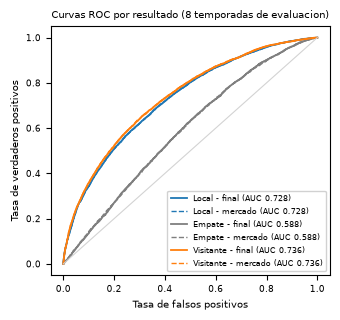

AUC macro modelo final: 0.6841 | mercado: 0.6839


In [10]:
# figura compacta de curvas ROC (una columna del informe): modelo final (continuo) y mercado crudo (discontinuo) para los tres resultados
from pathlib import Path
FIGDIR = Path('../../docs/figures'); FIGDIR.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(3.5, 3.3))
for j, (lab, col) in enumerate((('Local (H)', 'tab:blue'), ('Empate (D)', 'tab:gray'), ('Visitante (A)', 'tab:orange'))):
    for k, (nom, ls) in enumerate((('MODELO FINAL', '-'), ('mercado crudo (consenso)', '--'))):
        fpr, tpr, _ = roc_curve(y[EV] == j, REFS[nom][EV][:, j]); au = roc_auc_score(y[EV] == j, REFS[nom][EV][:, j])
        ax.plot(fpr, tpr, color=col, ls=ls, lw=1.3 if k == 0 else 1.0, label=f"{lab.split(' ')[0]} - {'final' if k == 0 else 'mercado'} (AUC {au:.3f})")
ax.plot([0, 1], [0, 1], color='lightgray', lw=0.8); ax.set_xlabel('Tasa de falsos positivos', fontsize=7); ax.set_ylabel('Tasa de verdaderos positivos', fontsize=7)
ax.tick_params(labelsize=6.5); ax.legend(fontsize=5.8, loc='lower right', framealpha=0.9); ax.set_title('Curvas ROC por resultado (8 temporadas de evaluacion)', fontsize=7.5)
plt.tight_layout(); fig.savefig(FIGDIR / 'final_roc_paper.png', dpi=250); plt.show()
print('AUC macro modelo final:', round(float(np.mean([roc_auc_score(y[EV] == j, P_fin[EV][:, j]) for j in range(3)])), 4), '| mercado:', round(float(np.mean([roc_auc_score(y[EV] == j, Pmk[EV][:, j]) for j in range(3)])), 4))

**Qué encontramos.** Las curvas del modelo final y del mercado crudo se superponen en los tres resultados: AUC 0.728 (local), 0.588 (empate) y 0.736 (visitante) en ambos; el AUC macro es 0.684.

**Qué significa para nuestro caso.** El modelo final no ordena mejor los partidos que el mercado; su ventaja es de calibración. El empate es el resultado peor discriminado por cualquiera de los dos.

## Resumen del modelo final

| Aspecto | Decisión / resultado |
|---|---|
| **Modelo** | Regresión logística multinomial estandarizada, `C = 0.01`, sobre 2 variables: `REF_logit = ln(pH/pA)` y `REF_pD` |
| **Precio de referencia** | Cuotas de **apertura** de Pinnacle (95.4% de los partidos); respaldo: consenso de B365, BW, WH y PS |
| **Qué se quitó** | `MKT_margin` (no estacionaria, PSI 0.6–1.5); plantilla, forma y habilidades (no aportan sobre el precio) |
| **Log loss (8 temporadas)** | **0.9652**; mercado crudo 0.9665; modelo anterior 0.9656; prior 1.0727 |
| **Frente al mercado** | −0.0013 [−0.0018, −0.0007], 7/8 temporadas, *p* ajustado 0.001 |
| **Discriminación** | AUC macro 0.684 (igual al mercado); empate 0.588 |
| **Calibración** | ECE 0.0076 (mercado 0.0134); pendientes 1.06 |
| **Corrección por liga** | Se probó un intercepto por liga (con y sin encogimiento): empeora (+0.0002 a +0.0003); no se usa |
| **Dónde mejora** | Portugal y Turquía (significativo tras BH); resto de ligas sin diferencias |
| **Dinero** | ROI en Pinnacle −1.4% [−6.3%, +3.0%]: no se detecta retorno positivo |
| **Archivos** | `modelo_final.json`, `modelo_final.joblib`, `modelo_final_oof.csv` |

**Lectura global.** El modelo final es el mejor de los probados, pero su ventaja es de refinamiento (corregir la subconfianza del precio), no de información nueva: la conclusión central del proyecto —el mercado es eficiente respecto a la información de fundamentos disponible— se mantiene.

**Limitaciones.** (1) En 2025/26 Pinnacle cubre 48% de los partidos, así que esa temporada se parece más al consenso. (2) La mejora por liga (Portugal, Turquía) viene de un único periodo y 9 comparaciones. (3) Las cuotas se asumen de apertura; usar cuotas de cierre como entrada sería una fuga. (4) El modelo da probabilidades, no recomendaciones de apuesta.